# 3. Filtering, Morphology and the Camera Model

Practice for module 3: 1D sliding windows (correlation vs convolution), common filters and ReLU / MaxPool,
2D filtering with im2col, morphological operations, and projecting 3D points to pixels.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80

## 3.1 1D cross-correlation vs convolution

Correlation slides the filter as is; convolution flips it first. For a symmetric filter they are the same.

In [2]:
def correlate1d(x, k):
    n = len(k)
    return np.array([np.dot(x[i:i + n], k) for i in range(len(x) - n + 1)])

def convolve1d(x, k):
    return correlate1d(x, k[::-1])

x = np.array([0, 0, 1, 2, 3, 0, 0, 1, 2, 3, 0, 0], dtype=float)
pattern = np.array([1, 2, 3], dtype=float)

corr = correlate1d(x, pattern)
conv = convolve1d(x, pattern)
print("correlation:", corr, " peaks at", np.flatnonzero(corr == corr.max()))
print("convolution:", conv)
assert np.allclose(corr, np.correlate(x, pattern, mode="valid"))
assert np.allclose(conv, np.convolve(x, pattern, mode="valid"))

correlation: [ 3.  8. 14.  8.  3.  3.  8. 14.  8.  3.]  peaks at [2 7]
convolution: [ 1.  4. 10. 12.  9.  1.  4. 10. 12.  9.]


## 3.2 Mean, Gaussian and Laplacian filters on a noisy signal

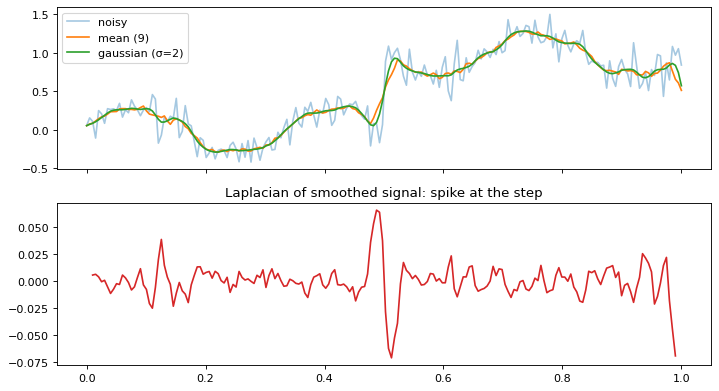

In [3]:
rng = np.random.default_rng(1)
t = np.linspace(0, 1, 200)
clean = np.where(t < 0.5, 0.0, 1.0) + 0.3 * np.sin(2 * np.pi * 3 * t)
noisy = clean + rng.normal(0, 0.15, t.size)

mean_k = np.ones(9) / 9
gx = np.arange(-4, 5); gauss_k = np.exp(-gx ** 2 / (2 * 2.0 ** 2)); gauss_k /= gauss_k.sum()
lap_k = np.array([1, -2, 1], dtype=float)

smooth_mean = np.convolve(noisy, mean_k, mode="same")
smooth_gauss = np.convolve(noisy, gauss_k, mode="same")
edges = np.convolve(smooth_gauss, lap_k, mode="same")

fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
axes[0].plot(t, noisy, alpha=0.4, label="noisy")
axes[0].plot(t, smooth_mean, label="mean (9)")
axes[0].plot(t, smooth_gauss, label="gaussian (σ=2)")
axes[0].legend()
axes[1].plot(t[2:-2], edges[2:-2], "C3"); axes[1].set_title("Laplacian of smoothed signal: spike at the step")
plt.tight_layout(); plt.show()

## 3.3 Non-linear operations: ReLU and MaxPool

In [4]:
relu = lambda v: np.maximum(0, v)

def maxpool1d(v, size=2, stride=2):
    return np.array([v[i:i + size].max() for i in range(0, len(v) - size + 1, stride)])

v = np.array([-2, 3, -1, 5, 0, -4, 2, 1], dtype=float)
print("x         :", v)
print("ReLU(x)   :", relu(v))
print("MaxPool(x):", maxpool1d(v))
# non-linearity: f(a + b) != f(a) + f(b)
a, b = np.array([-1.0]), np.array([2.0])
print("ReLU(a+b) =", relu(a + b), " ReLU(a)+ReLU(b) =", relu(a) + relu(b))

x         : [-2.  3. -1.  5.  0. -4.  2.  1.]
ReLU(x)   : [0. 3. 0. 5. 0. 0. 2. 1.]
MaxPool(x): [3. 5. 0. 2.]
ReLU(a+b) = [1.]  ReLU(a)+ReLU(b) = [2.]


## 3.4 2D filtering with im2col

Each `K×K` window becomes a column, so filtering is one matrix multiplication.
Output size: `floor((N + 2P - K) / S) + 1`.

In [5]:
def out_size(n, k, p, s):
    return (n + 2 * p - k) // s + 1

def im2col(img, k, pad=0, stride=1):
    img = np.pad(img, pad)
    H, W = img.shape
    oh, ow = (H - k) // stride + 1, (W - k) // stride + 1
    cols = np.empty((k * k, oh * ow))
    for i in range(oh):
        for j in range(ow):
            cols[:, i * ow + j] = img[i * stride:i * stride + k, j * stride:j * stride + k].ravel()
    return cols, (oh, ow)

def filter2d(img, kernel, pad=0, stride=1):
    k = kernel.shape[0]
    cols, shape = im2col(img, k, pad, stride)
    return (kernel.ravel() @ cols).reshape(shape)

for n, k, p, s in [(32, 3, 0, 1), (32, 3, 1, 1), (32, 3, 1, 2), (32, 5, 0, 1)]:
    print(f"N={n} K={k} P={p} S={s} -> {out_size(n, k, p, s)}")

N=32 K=3 P=0 S=1 -> 30
N=32 K=3 P=1 S=1 -> 32
N=32 K=3 P=1 S=2 -> 16
N=32 K=5 P=0 S=1 -> 28


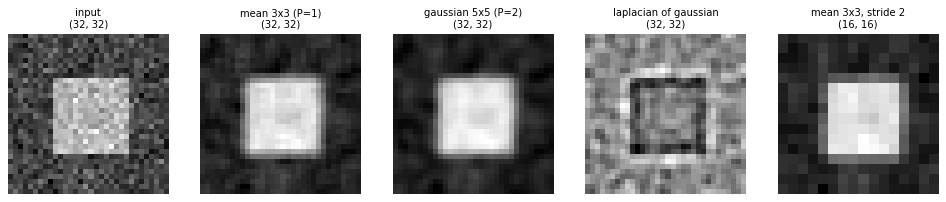

In [6]:
N = 32
yy, xx = np.mgrid[0:N, 0:N]
img = ((xx > 8) & (xx < 24) & (yy > 8) & (yy < 24)).astype(float)
img += np.random.default_rng(2).normal(0, 0.2, img.shape)

mean3 = np.ones((3, 3)) / 9
g = np.exp(-(np.arange(-2, 3) ** 2) / 2.0); gauss5 = np.outer(g, g); gauss5 /= gauss5.sum()
lap = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=float)

results = {
    "input": img,
    "mean 3x3 (P=1)": filter2d(img, mean3, pad=1),
    "gaussian 5x5 (P=2)": filter2d(img, gauss5, pad=2),
    "laplacian of gaussian": filter2d(filter2d(img, gauss5, pad=2), lap, pad=1),
    "mean 3x3, stride 2": filter2d(img, mean3, pad=1, stride=2),
}
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, (t, im) in zip(axes, results.items()):
    ax.imshow(im, cmap="gray"); ax.set_title(f"{t}\n{im.shape}", fontsize=9); ax.axis("off")
plt.show()

## 3.5 Morphological operations

Dilation = max over the neighborhood, erosion = min. Open, close and gradient are built from them.

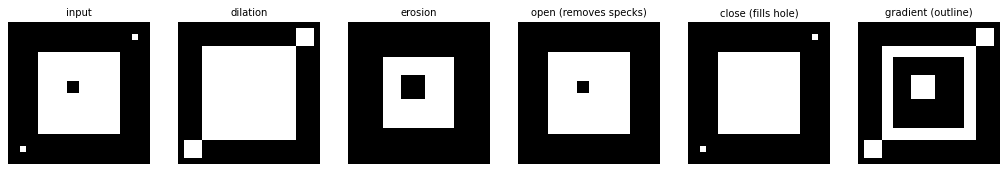

In [7]:
def morph(img, k=3, op=np.max):
    pad = k // 2
    fill = 0 if op is np.max else 1
    p = np.pad(img, pad, constant_values=fill)
    out = np.empty_like(img)
    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            out[i, j] = op(p[i:i + k, j:j + k])
    return out

dilate = lambda im: morph(im, op=np.max)
erode = lambda im: morph(im, op=np.min)
opening = lambda im: dilate(erode(im))
closing = lambda im: erode(dilate(im))
grad = lambda im: dilate(im) - erode(im)

B = np.zeros((24, 24))
B[5:19, 5:19] = 1        # main object
B[10:12, 10:12] = 0      # small hole
B[2, 21] = B[21, 2] = 1  # specks of noise

ops = {"input": B, "dilation": dilate(B), "erosion": erode(B),
       "open (removes specks)": opening(B), "close (fills hole)": closing(B), "gradient (outline)": grad(B)}
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for ax, (t, im) in zip(axes, ops.items()):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1); ax.set_title(t, fontsize=9); ax.axis("off")
plt.show()

## 3.6 Camera model: rotation, extrinsics, intrinsics, projection

world → `[R | t]` → camera coordinates → `K` → pixels: `u = f·X/Z + cx`, `v = f·Y/Z + cy`.

det(R) = 1.0  R^T R = I: True


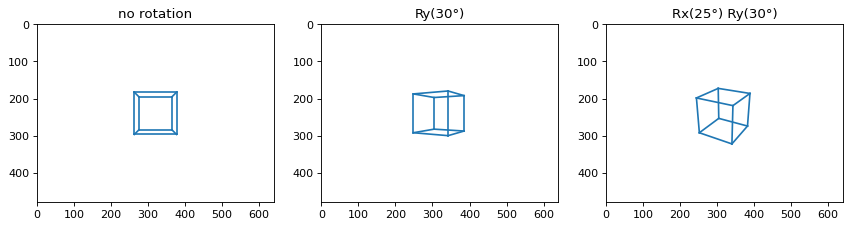

In [8]:
def Rx(deg):
    t = np.deg2rad(deg); c, s = np.cos(t), np.sin(t)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])

def Ry(deg):
    t = np.deg2rad(deg); c, s = np.cos(t), np.sin(t)
    return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])

def Rz(deg):
    t = np.deg2rad(deg); c, s = np.cos(t), np.sin(t)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])

# rotations preserve lengths and have det = 1 (no scaling)
R = Rz(20) @ Ry(30)
print("det(R) =", round(np.linalg.det(R), 6), " R^T R = I:", np.allclose(R.T @ R, np.eye(3)))

# unit cube
cube = np.array([[x, y, z] for x in (0, 1) for y in (0, 1) for z in (0, 1)], dtype=float).T - 0.5
edges = [(a, b) for a in range(8) for b in range(a + 1, 8) if np.sum(np.abs(cube[:, a] - cube[:, b])) == 1]

f, cx, cy = 400, 320, 240
K = np.array([[f, 0, cx], [0, f, cy], [0, 0, 1]])
t_vec = np.array([[0], [0], [4.0]])  # cube 4 units in front of the camera

def project(points, R, t, K):
    cam = R @ points + t          # extrinsics: world -> camera
    pix = K @ cam                 # intrinsics: camera -> image plane
    return pix[:2] / pix[2]       # perspective divide

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (title, Rm) in zip(axes, [("no rotation", np.eye(3)), ("Ry(30°)", Ry(30)), ("Rx(25°) Ry(30°)", Rx(25) @ Ry(30))]):
    uv = project(cube, Rm, t_vec, K)
    for a, b in edges:
        ax.plot(uv[0, [a, b]], uv[1, [a, b]], "C0")
    ax.set_xlim(0, 640); ax.set_ylim(480, 0); ax.set_aspect("equal"); ax.set_title(title)
plt.show()

## Summary

- Correlation = sliding dot product; convolution flips the filter first.
- Mean / Gaussian smooth, Laplacian finds edges; ReLU and MaxPool are non-linear.
- im2col turns filtering into matrix multiplication; output size `floor((N + 2P - K)/S) + 1`.
- Morphology: dilation (max), erosion (min), open, close, gradient.
- Projection: world → `[R | t]` → camera → `K` → pixels.